In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

retail_df = pd.read_csv('retail_prices.csv', parse_dates=['date'])
cpi_df = pd.read_csv('cpi.csv', parse_dates=['date'])

display(retail_df.head(2))
display(cpi_df.head(2))

,date,food_type,sub_category,commodity,price
0,2020-01-01,Calorie-Dense,Cereals,"RICE, REGULAR-MILLED, 1 KG",35.80
1,2020-02-01,Calorie-Dense,Cereals,"RICE, REGULAR-MILLED, 1 KG",35.92


,date,income_group,food_type,sub_category,cpi
0,2020-01-01,All Income,Baseline,ALL ITEMS,103.9
1,2020-02-01,All Income,Baseline,ALL ITEMS,103.4


In [14]:
# calculate inflation
rq1 = retail_df.groupby(['date', 'food_type'])['price'].mean().reset_index()
rq1['inf'] = rq1.groupby('food_type')['price'].pct_change(12) * 100
rq1 = rq1.dropna(subset=['inf'])

cal = rq1[rq1['food_type'] == 'Calorie-Dense']['inf']
nut = rq1[rq1['food_type'] == 'Nutrient-Dense']['inf']

# distribution checks
print(f"Shapiro Cal: {stats.shapiro(cal)[1]:.4f}")
print(f"Shapiro Nut: {stats.shapiro(nut)[1]:.4f}")

# 0.0839 and 0.0674 are both above 0.05, so we can assume normality for both distributions

# jump straight to t-test
t_stat, p_val = stats.ttest_ind(nut, cal, equal_var=False)
print(f"T-test stat: {t_stat:.4f} | p: {p_val:.4f}")

Shapiro Cal: 0.0839
Shapiro Nut: 0.0674
T-test stat: -1.2732 | p: 0.2052


In [ ]:
# get baseline inflation
base = cpi_df[cpi_df['sub_category'] == 'ALL ITEMS'].copy()
base['inf'] = base.groupby('income_group')['cpi'].pct_change(12) * 100
rq2 = base.dropna(subset=['inf'])

b30 = rq2[rq2['income_group'] == 'Bottom 30%']['inf'].values
all_inc = rq2[rq2['income_group'] == 'All Income']['inf'].values

# distribution checks
print(f"Shapiro B30: {stats.shapiro(b30)[1]:.4e}")
print(f"Shapiro All: {stats.shapiro(all_inc)[1]:.4e}")

# 2.6891e-04 and 2.9620e-05 are both below 0.05, so we reject the null hypothesis of normality for both distributions

# jump straight to wilcoxon
stat, p_val = stats.wilcoxon(b30, all_inc, alternative='greater')
print(f"Wilcoxon stat: {stat:.4f} | p: {p_val:.4e}")

Shapiro B30: 2.6891e-04
Shapiro All: 2.9620e-05
Wilcoxon stat: 1888.0000 | p: 6.2436e-06


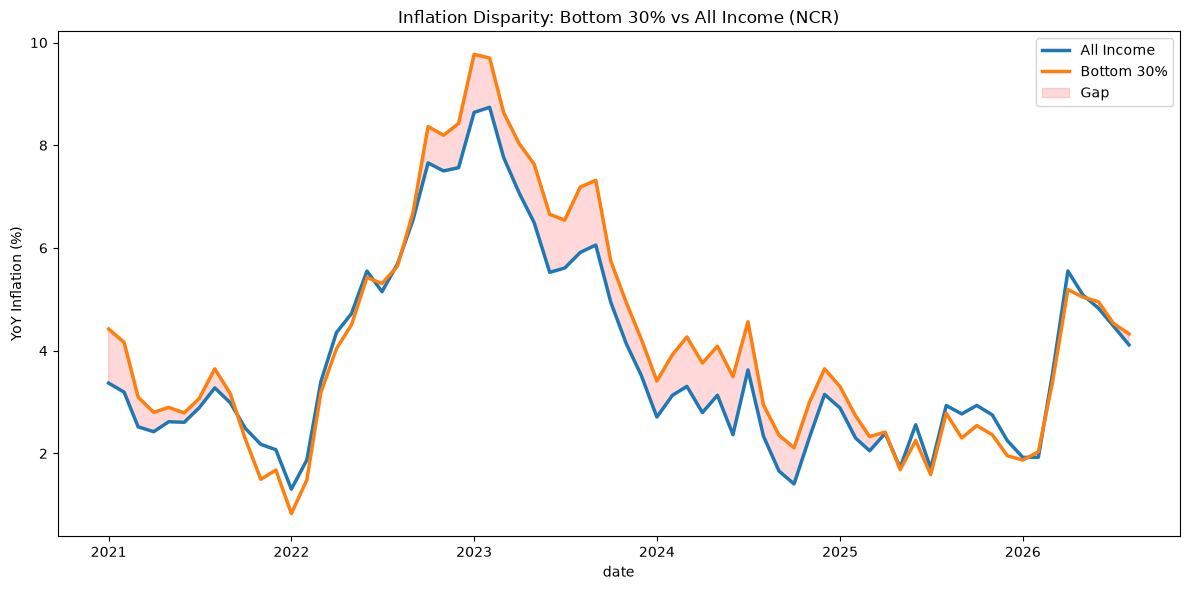

In [16]:
plt.figure(figsize=(12, 6))

piv = rq2.pivot(index='date', columns='income_group', values='inf').dropna()
sns.lineplot(data=rq2, x='date', y='inf', hue='income_group', lw=2.5)
plt.fill_between(piv.index, piv['All Income'], piv['Bottom 30%'], where=(piv['Bottom 30%'] > piv['All Income']), color='red', alpha=0.15, label='Gap')

plt.title('Inflation Disparity: Bottom 30% vs All Income (NCR)')
plt.ylabel('YoY Inflation (%)')

h, l = plt.gca().get_legend_handles_labels()
plt.legend(h, l)

plt.tight_layout()
plt.savefig('../static/rq2_gap.png')

Slope: -1.170833e-04 | p-val: 4.1786e-07


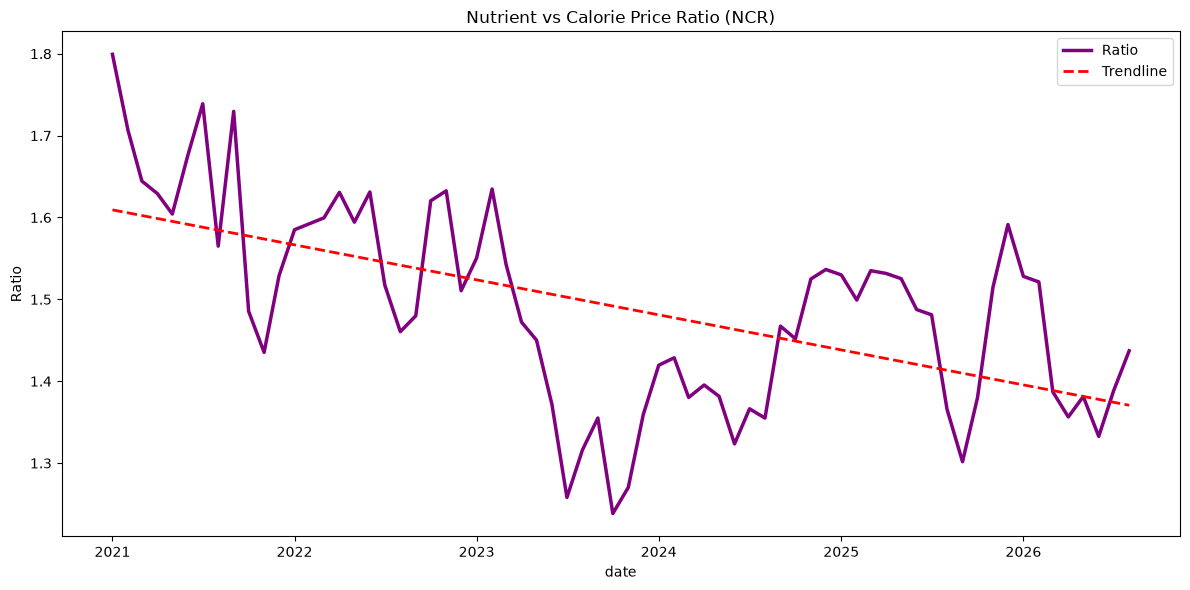

In [17]:
import matplotlib.dates as mdates

# pivot and get ratio
piv = rq1.pivot(index='date', columns='food_type', values='price').dropna()
piv['ratio'] = piv['Nutrient-Dense'] / piv['Calorie-Dense']

# trend test
x = mdates.date2num(piv.index)
y = piv['ratio']
slope, intcpt, r, p_val, err = stats.linregress(x, y)

print(f"Slope: {slope:.6e} | p-val: {p_val:.4e}")

# plot
plt.figure(figsize=(12, 6))
sns.lineplot(x=piv.index, y=y, color='purple', lw=2.5, label='Ratio')
plt.plot(piv.index, intcpt + slope * x, 'r--', lw=2, label='Trendline')

plt.title('Nutrient vs Calorie Price Ratio (NCR)')
plt.ylabel('Ratio')
plt.legend()
plt.tight_layout()
plt.savefig('../static/rq3_ratio.png')

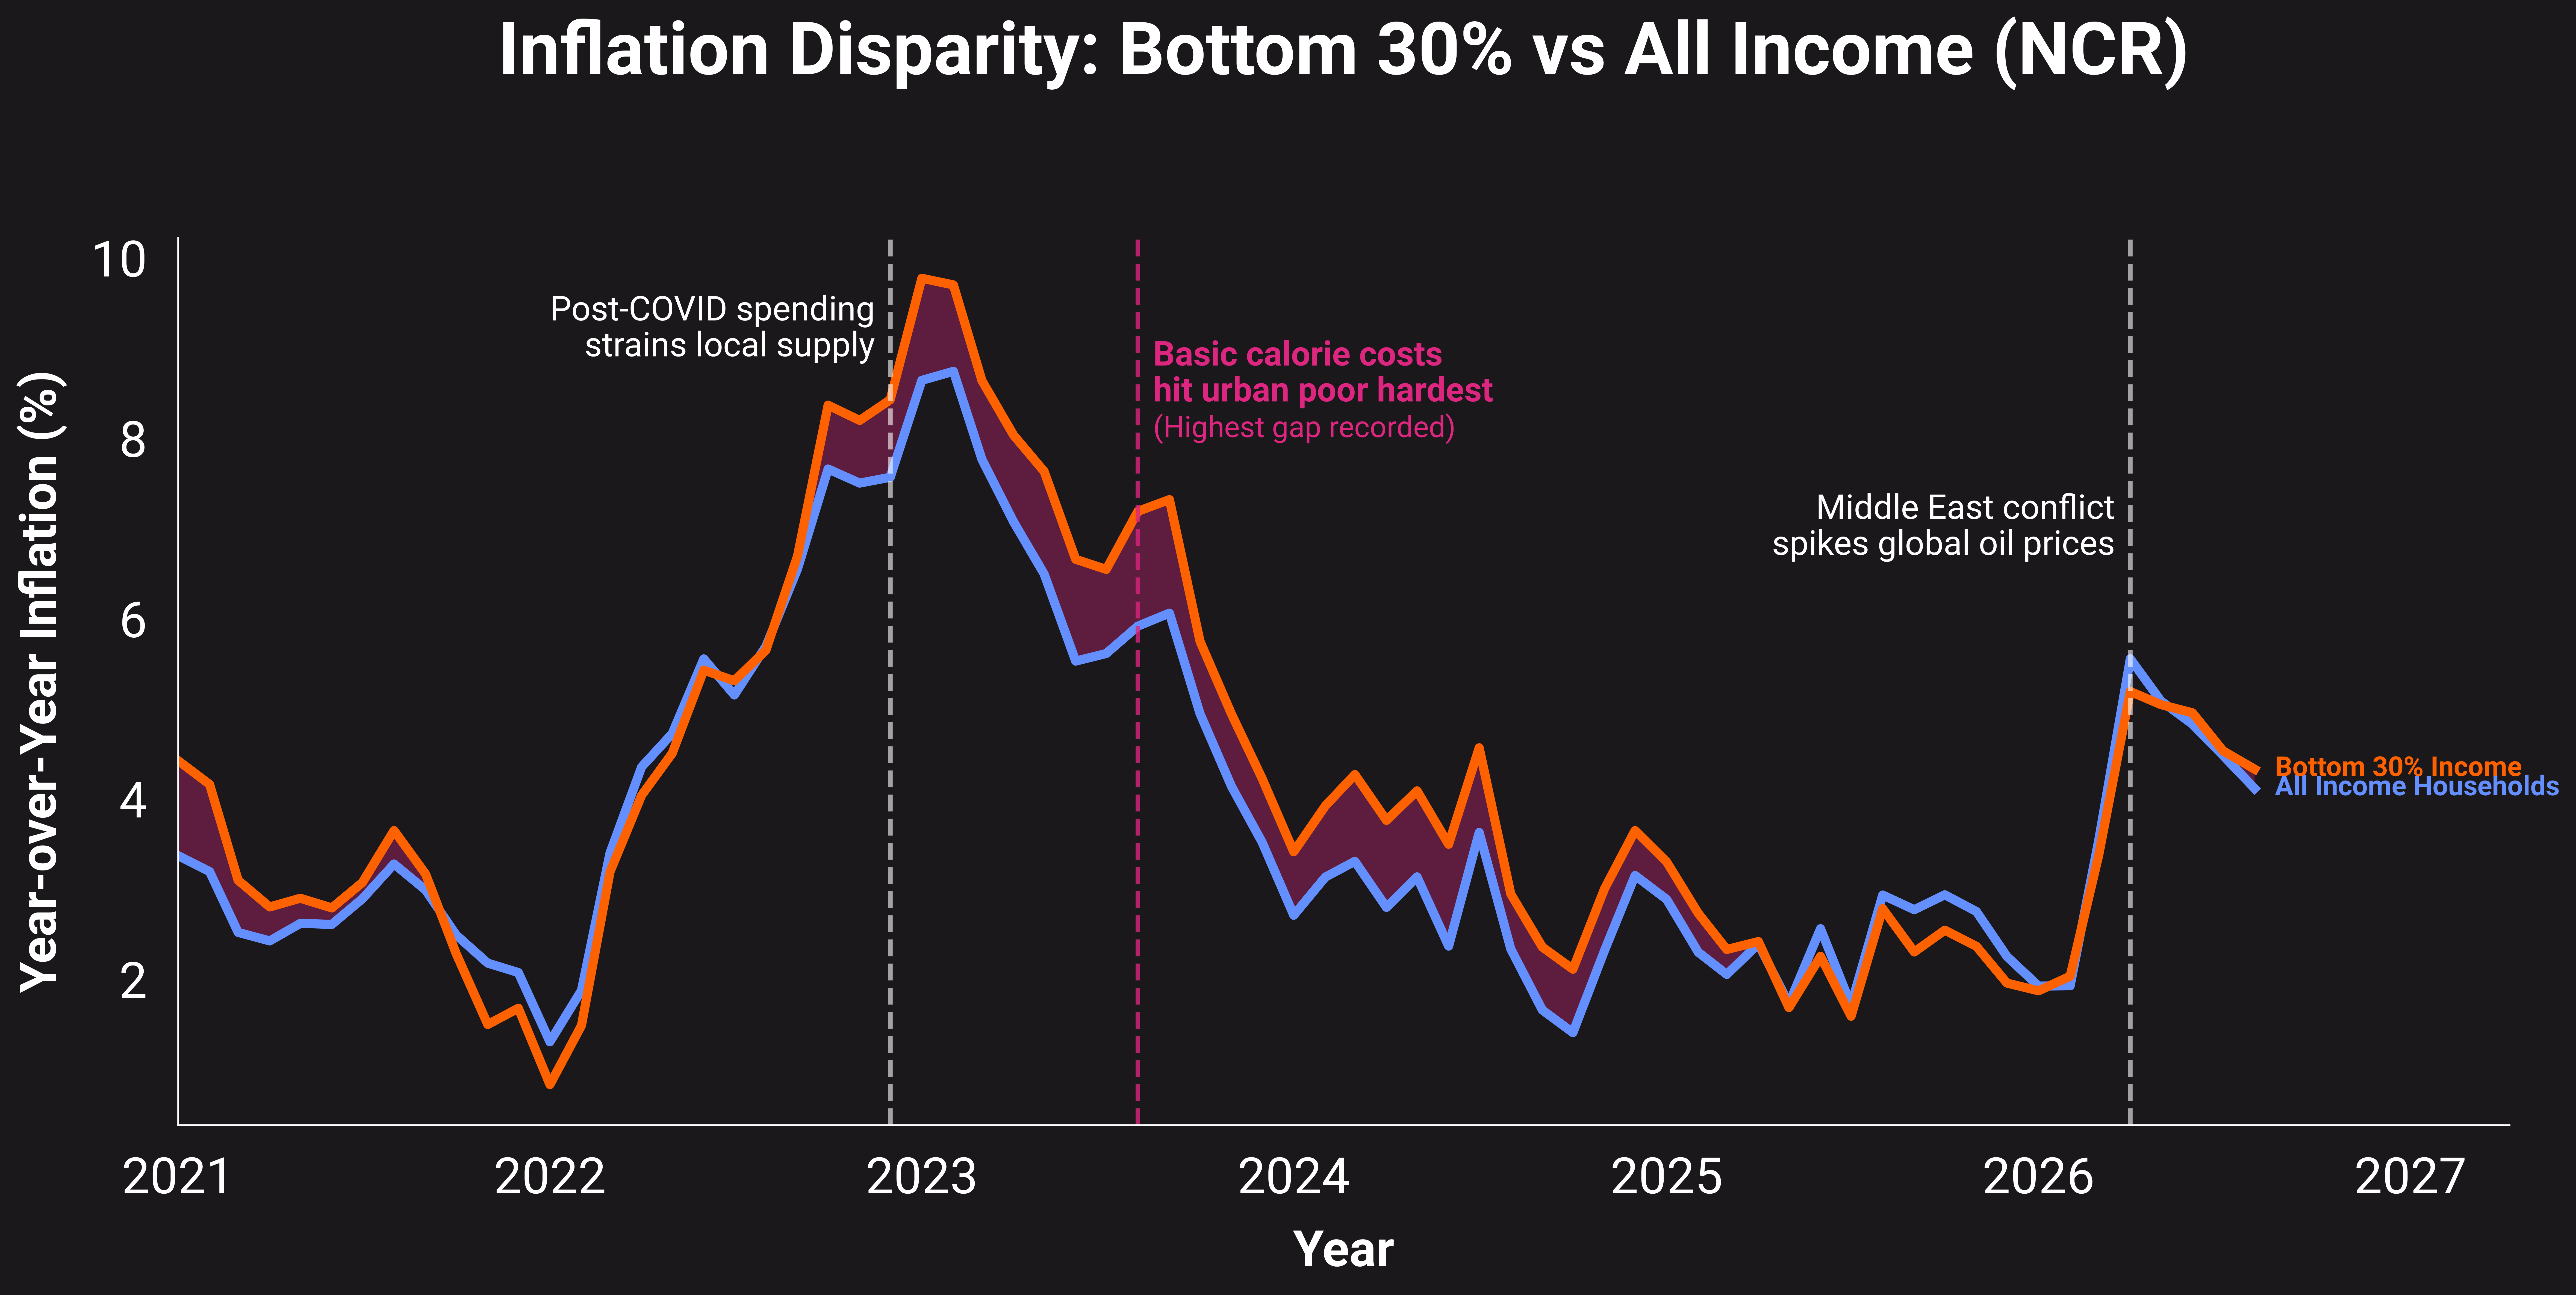

In [46]:
import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

# !wget 'https://github.com/openmaptiles/fonts/raw/master/roboto/Roboto-Light.ttf'
# !wget 'https://github.com/openmaptiles/fonts/raw/master/roboto/Roboto-Regular.ttf'
# !wget 'https://github.com/openmaptiles/fonts/raw/master/roboto/Roboto-Medium.ttf'
# !wget 'https://github.com/openmaptiles/fonts/raw/master/roboto/Roboto-Bold.ttf'

from matplotlib import font_manager as fm
for font_file in fm.findSystemFonts('.'):
    fm.fontManager.addfont(font_file)

color_bg = "#1B181C"
color_text = "#FFFFFF"
colors = ["#648FFF", "#785EF0", "#DC267F", "#FE6100", "#FFB000", "#000000", "#FFFFFF"]

# @title Plot settings
mpl.rcParams['figure.dpi'] = 600
mpl.rcParams["figure.figsize"] = 16,8

# Text
mpl.rcParams['font.family'] = 'Roboto'

# Title
mpl.rcParams['figure.titlesize'] = 32
mpl.rcParams['axes.titlesize'] = 32
mpl.rcParams['axes.titleweight'] = 'bold'

# Labels
mpl.rcParams['axes.labelsize'] = 22
mpl.rcParams['xtick.labelsize'] = 22
mpl.rcParams['ytick.labelsize'] = 22

# Spacing
mpl.rcParams['axes.titlepad'] = 72
mpl.rcParams['axes.labelpad'] = 10
mpl.rcParams['xtick.major.pad'] = 10
mpl.rcParams['ytick.major.pad'] = 10
mpl.rcParams['xtick.major.width'] = 0
mpl.rcParams['xtick.minor.width'] = 0
mpl.rcParams['ytick.major.width'] = 0
mpl.rcParams['ytick.minor.width'] = 0

# Spines and grids
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.grid'] = False

# Legends
mpl.rcParams['legend.title_fontsize'] = 18
mpl.rcParams['legend.fontsize'] = 18
mpl.rcParams['legend.frameon'] = False

# Bars
plt.rcParams['patch.linewidth'] = 0
plt.rcParams['patch.edgecolor'] = 'none'

# Colors
mpl.rcParams["figure.facecolor"] = color_bg
mpl.rcParams["axes.facecolor"] = color_bg
mpl.rcParams["savefig.facecolor"] = color_bg

# Text colors
mpl.rcParams['text.color'] = color_text
mpl.rcParams['axes.labelcolor'] = color_text
mpl.rcParams['xtick.color'] = color_text
mpl.rcParams['ytick.color'] = color_text

# Line colors
mpl.rcParams['axes.edgecolor'] = color_text

plt.figure()

piv = rq2.pivot(index='date', columns='income_group', values='inf').dropna()
piv['gap'] = piv['Bottom 30%'] - piv['All Income']

plt.plot(piv.index, piv['All Income'], color=colors[0], linewidth=4)
plt.plot(piv.index, piv['Bottom 30%'], color=colors[3], linewidth=4)
plt.fill_between(piv.index, piv['All Income'], piv['Bottom 30%'], where=(piv['Bottom 30%'] > piv['All Income']), color=colors[2], alpha=0.35)

last_date = piv.index[-1]
val_all = piv['All Income'].iloc[-1]
val_bot = piv['Bottom 30%'].iloc[-1]

text_offset = pd.DateOffset(days=20)
plt.text(last_date + text_offset, val_all, 'All Income Households', color=colors[0], fontsize=12, fontweight='bold', va='center')
plt.text(last_date + text_offset, val_bot, 'Bottom 30% Income', color=colors[3], fontsize=12, fontweight='bold', va='center')

# events
max_gap_date = piv['gap'].idxmax()
supply_shock = pd.to_datetime('2022-12-01')
oil_shock = pd.to_datetime('2026-04-01')

# event dashed lines
plt.axvline(x=max_gap_date, color=colors[2], linestyle='--', linewidth=2, alpha=0.8)
plt.axvline(x=supply_shock, color=colors[6], linestyle='--', linewidth=2, alpha=0.6) 
plt.axvline(x=oil_shock, color=colors[6], linestyle='--', linewidth=2, alpha=0.6)

plt.text(supply_shock - pd.DateOffset(days=15), 9.2, 'Post-COVID spending\nstrains local supply', color=color_text, fontsize=15, ha='right', va='center')
plt.text(oil_shock - pd.DateOffset(days=15), 7, 'Middle East conflict\nspikes global oil prices', color=color_text, fontsize=15, ha='right', va='center')

# highest gap
plt.text(max_gap_date + pd.DateOffset(days=15), 8.7, 'Basic calorie costs\nhit urban poor hardest', color=colors[2], fontsize=15, fontweight='bold', ha='left', va='center')
plt.text(max_gap_date + pd.DateOffset(days=15), 8.1, '(Highest gap recorded)', color=colors[2], fontsize=13, ha='left', va='center')

plt.title('Inflation Disparity: Bottom 30% vs All Income (NCR)')
plt.xlabel('Year', fontweight='bold', fontsize=22)
plt.ylabel('Year-over-Year Inflation (%)', fontweight='bold', fontsize=22)

plt.xlim(piv.index[0], last_date + pd.DateOffset(days=250)) 

plt.tight_layout()
plt.savefig('../static/nutshell_base.pdf', format='pdf', bbox_inches='tight')
plt.show()